# Image Dataset Loader Validation

This notebook verifies the real image loaders before model training.

Success requires correct availability, shapes, ranges, subsets, seeds, and deterministic repeats.

The notebook does not train a model or calculate memorization metrics.


In [1]:
# Import the small set of tools used for loader validation.
from pathlib import Path
import sys

# Find the repository root from either the root or notebook directory.
start_path = Path.cwd().resolve()
search_paths = (start_path, *start_path.parents)
REPO_ROOT = next(
    path for path in search_paths
    if (path / "mem_param_src").is_dir() and (path / "pyproject.toml").exists()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torchvision.utils import make_grid

from mem_param_src.config import get_base_config
from mem_param_src.datasets import build_data_bundle

# Use the resolved data root and a readable plot scale.
DATA_ROOT = REPO_ROOT / "data"
plt.rcParams.update({"figure.dpi": 110})


## 1. Check local datasets

Confirm each required local dataset before loader tests.

AFHQ-v2 and FFHQ128 remain visible as unavailable external datasets.


In [2]:
# Define the complete dataset and experiment matrix.
DATASET_PATHS = {
    "mnist": DATA_ROOT / "MNIST" / "raw" / "train-images-idx3-ubyte",
    "cifar10": DATA_ROOT / "cifar-10-batches-py" / "data_batch_1",
    "flowers102": DATA_ROOT / "flowers-102" / "jpg",
    "celeba32_grey": DATA_ROOT / "celeba" / "img_align_celeba",
    "afhq_v2": DATA_ROOT / "afhq_v2",
    "ffhq128": DATA_ROOT / "ffhq" / "thumbnails128x128",
}
REQUIRED_DATASETS = ("mnist", "cifar10", "flowers102", "celeba32_grey")
DISPLAY_NAMES = {
    "mnist": "MNIST",
    "cifar10": "CIFAR-10",
    "flowers102": "Flowers102",
    "celeba32_grey": "CelebA",
    "afhq_v2": "AFHQ-v2",
    "ffhq128": "FFHQ128",
}
CANONICAL_CHANNELS = {
    "mnist": 1,
    "cifar10": 3,
    "flowers102": 3,
    "celeba32_grey": 1,
}
IMAGE_SIZES = (16, 32, 64, 512)
IMAGE_CHANNELS = (1, 3)
TRAIN_COUNTS = (4, 8, 16)
SEEDS = (7, 19)


In [3]:
# Show which local datasets can enter the real loader checks.
inventory_rows = []
for dataset_key, path in DATASET_PATHS.items():
    available = path.exists()
    required = dataset_key in REQUIRED_DATASETS
    inventory_rows.append(
        {
            "dataset": DISPLAY_NAMES[dataset_key],
            "required": required,
            "available": available,
            "status": "PASS" if available else "NOT TESTED",
            "expected_path": str(path),
        }
    )

inventory = pd.DataFrame(inventory_rows)
display(inventory)

# Stop when one required local dataset is unavailable.
required_ready = inventory.query("required")["available"].all()
assert required_ready, "A required local dataset is unavailable."
print("PASS: all four required local datasets are available.")


,dataset,required,available,status,expected_path
0,MNIST,True,True,PASS,/Users/mohammadaljaff/Desktop/PhD/projects/mem...
1,CIFAR-10,True,True,PASS,/Users/mohammadaljaff/Desktop/PhD/projects/mem...
2,Flowers102,True,True,PASS,/Users/mohammadaljaff/Desktop/PhD/projects/mem...
3,CelebA,True,True,PASS,/Users/mohammadaljaff/Desktop/PhD/projects/mem...
4,AFHQ-v2,False,False,NOT TESTED,/Users/mohammadaljaff/Desktop/PhD/projects/mem...
5,FFHQ128,False,False,NOT TESTED,/Users/mohammadaljaff/Desktop/PhD/projects/mem...


PASS: all four required local datasets are available.


## 2. Define one loader contract

Use the repository dispatcher for every dataset.

Keep `download=False` so this notebook proves local data readiness.


In [4]:
# Build one compact configuration for each loader request.
def make_config(dataset_key, image_size, channels, n_train, seed):
    config = get_base_config()
    config.study.dataset_key = dataset_key
    config.data.dataset = dataset_key
    config.data.root = str(DATA_ROOT)
    config.data.download = False
    config.data.n_train = n_train
    config.data.n_test = 4
    config.data.image_size = image_size
    config.data.resize_size = image_size
    config.data.image_channels = channels
    config.data.flatten = False
    config.data.train_split = "train"
    config.data.reference_split = "valid"
    config.training.seed = seed
    return config


# Cache repeated requests without changing loader behavior.
bundle_cache = {}


def load_bundle(dataset_key, image_size, channels, n_train, seed):
    key = (dataset_key, image_size, channels, n_train, seed)
    if key not in bundle_cache:
        config = make_config(*key)
        bundle_cache[key] = build_data_bundle(config)
    return bundle_cache[key]


# Assert the shared tensor and identity contract.
def assert_bundle(bundle, n_train, channels, image_size):
    expected_train = (n_train, channels, image_size, image_size)
    expected_reference = (4, channels, image_size, image_size)
    assert tuple(bundle["train"].shape) == expected_train
    assert tuple(bundle["reference"].shape) == expected_reference
    assert torch.isfinite(bundle["train"]).all()
    assert torch.isfinite(bundle["reference"]).all()
    assert float(bundle["train"].min()) >= -1.0
    assert float(bundle["train"].max()) <= 1.0
    assert len(bundle["train_sample_ids"]) == n_train
    assert len(set(bundle["train_sample_ids"])) == n_train
    assert bundle["train_source_id"] != bundle["reference_source_id"]


# Convert fixed-range tensors into display images.
def grid_image(images, nrow=2):
    values = images.detach().cpu().add(1.0).div(2.0).clamp(0.0, 1.0)
    grid = make_grid(values, nrow=nrow, padding=2, pad_value=0.0)
    if grid.shape[0] == 1:
        return grid.squeeze(0).numpy(), "gray"
    return grid.permute(1, 2, 0).numpy(), None


## 3. Prove the minimal baseline

Load four training images and four held-out images from every required dataset.


In [5]:
# Load one canonical 32-pixel bundle from each required dataset.
baseline_bundles = {}
baseline_rows = []
for dataset_key in REQUIRED_DATASETS:
    channels = CANONICAL_CHANNELS[dataset_key]
    bundle = load_bundle(dataset_key, 32, channels, 4, 7)
    assert_bundle(bundle, 4, channels, 32)
    baseline_bundles[dataset_key] = bundle
    baseline_rows.append(
        {
            "dataset": DISPLAY_NAMES[dataset_key],
            "train_shape": tuple(bundle["train"].shape),
            "reference_shape": tuple(bundle["reference"].shape),
            "train_source_size": bundle["train_source_size"],
            "reference_source_size": bundle["reference_source_size"],
            "status": "PASS",
        }
    )

baseline_summary = pd.DataFrame(baseline_rows)
display(baseline_summary)
assert len(baseline_summary) == 4
print("PASS: every baseline bundle satisfies the shared contract.")


,dataset,train_shape,reference_shape,train_source_size,reference_source_size,status
0,MNIST,"(4, 1, 32, 32)","(4, 1, 32, 32)",60000,10000,PASS
1,CIFAR-10,"(4, 3, 32, 32)","(4, 3, 32, 32)",50000,10000,PASS
2,Flowers102,"(4, 3, 32, 32)","(4, 3, 32, 32)",1020,1020,PASS
3,CelebA,"(4, 1, 32, 32)","(4, 1, 32, 32)",162770,19867,PASS


PASS: every baseline bundle satisfies the shared contract.


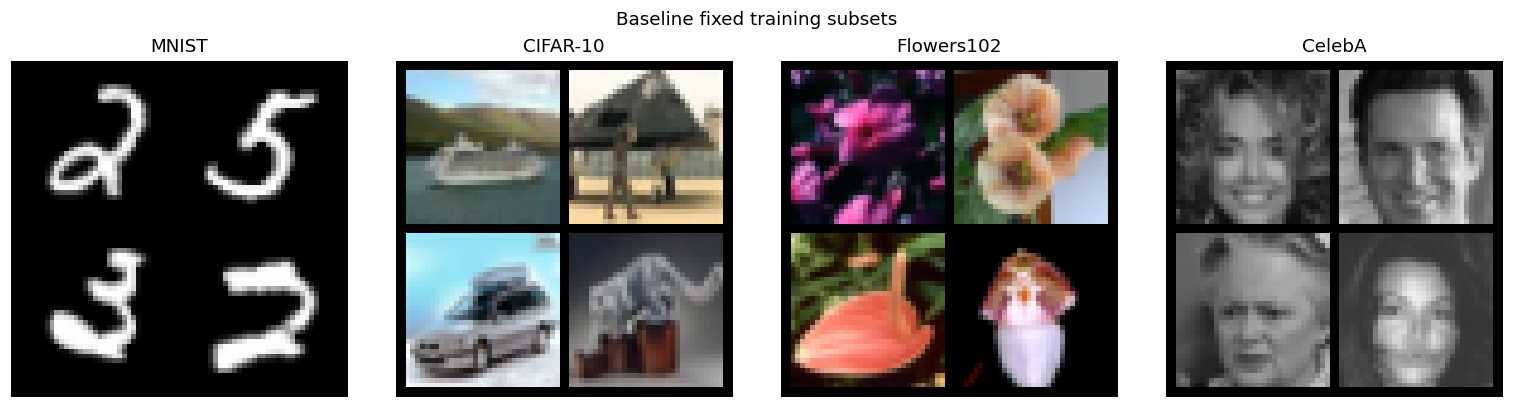

In [6]:
# Render the exact baseline training tensors.
figure, axes = plt.subplots(1, 4, figsize=(14, 3.6), constrained_layout=True)
for axis, dataset_key in zip(axes, REQUIRED_DATASETS):
    image, color_map = grid_image(baseline_bundles[dataset_key]["train"])
    axis.imshow(image, cmap=color_map, interpolation="nearest")
    axis.set_title(DISPLAY_NAMES[dataset_key])
    axis.axis("off")
figure.suptitle("Baseline fixed training subsets")
plt.show()


## 4. Check image size and channels

Test 16, 32, 64, and 512 pixels with one or three channels.

MNIST RGB repeats grayscale values. This mode adds no color information.

The 512-pixel variants test shape handling. They add no source detail.


In [7]:
# Load and assert every requested size and channel combination.
variant_bundles = {}
variant_rows = []
for dataset_key in REQUIRED_DATASETS:
    matched_indices = None
    for channels in IMAGE_CHANNELS:
        for image_size in IMAGE_SIZES:
            bundle = load_bundle(dataset_key, image_size, channels, 4, 7)
            assert_bundle(bundle, 4, channels, image_size)
            if matched_indices is None:
                matched_indices = bundle["train_indices"].clone()
            assert torch.equal(bundle["train_indices"], matched_indices)
            variant_bundles[(dataset_key, channels, image_size)] = bundle
            variant_rows.append(
                {
                    "dataset": DISPLAY_NAMES[dataset_key],
                    "channels": channels,
                    "image_size": image_size,
                    "shape": tuple(bundle["train"].shape),
                    "status": "PASS",
                }
            )

variant_summary = pd.DataFrame(variant_rows)
assert len(variant_summary) == 32
display(variant_summary)
print("PASS: all 32 size and channel variants use matched identities.")


,dataset,channels,image_size,shape,status
0,MNIST,1,16,"(4, 1, 16, 16)",PASS
1,MNIST,1,32,"(4, 1, 32, 32)",PASS
2,MNIST,1,64,"(4, 1, 64, 64)",PASS
3,MNIST,1,512,"(4, 1, 512, 512)",PASS
4,MNIST,3,16,"(4, 3, 16, 16)",PASS
5,MNIST,3,32,"(4, 3, 32, 32)",PASS
6,MNIST,3,64,"(4, 3, 64, 64)",PASS
7,MNIST,3,512,"(4, 3, 512, 512)",PASS
8,CIFAR-10,1,16,"(4, 1, 16, 16)",PASS
9,CIFAR-10,1,32,"(4, 1, 32, 32)",PASS


PASS: all 32 size and channel variants use matched identities.


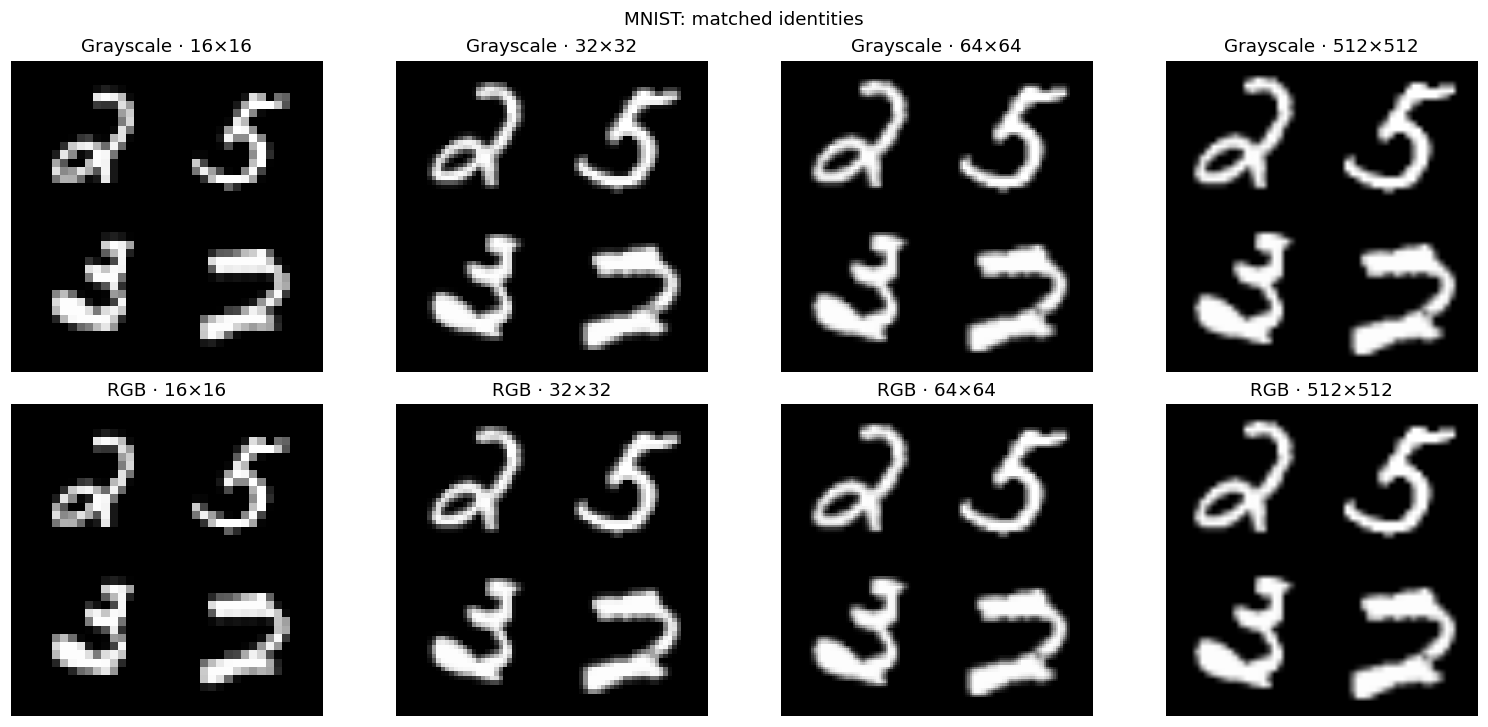

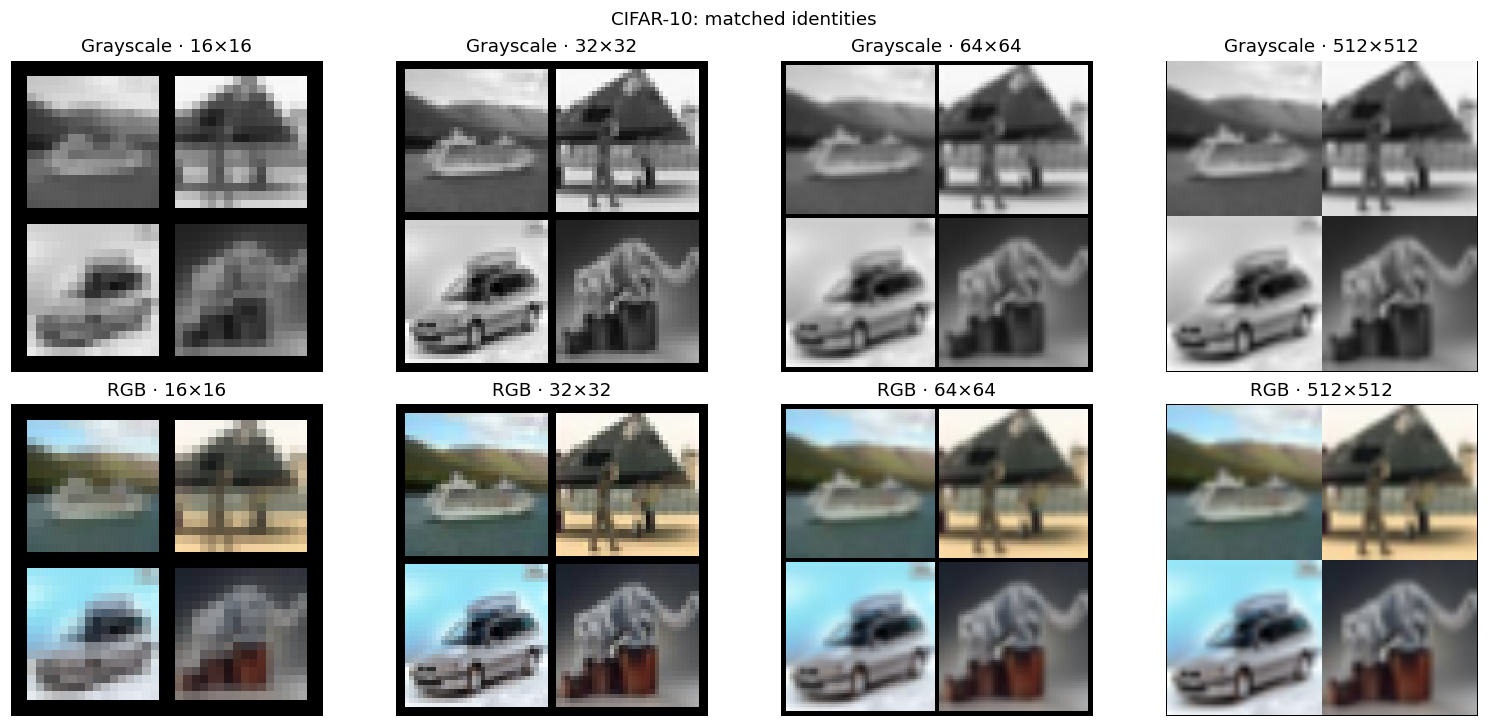

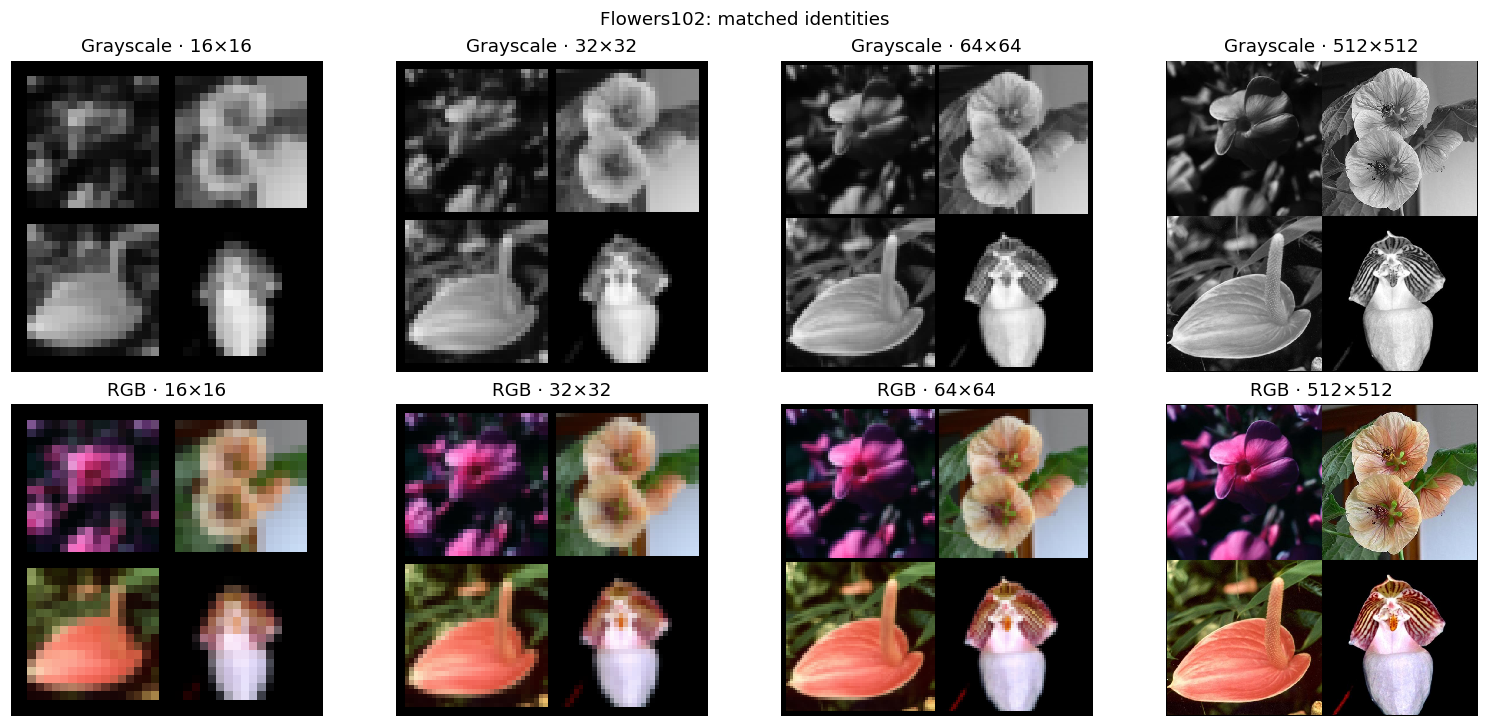

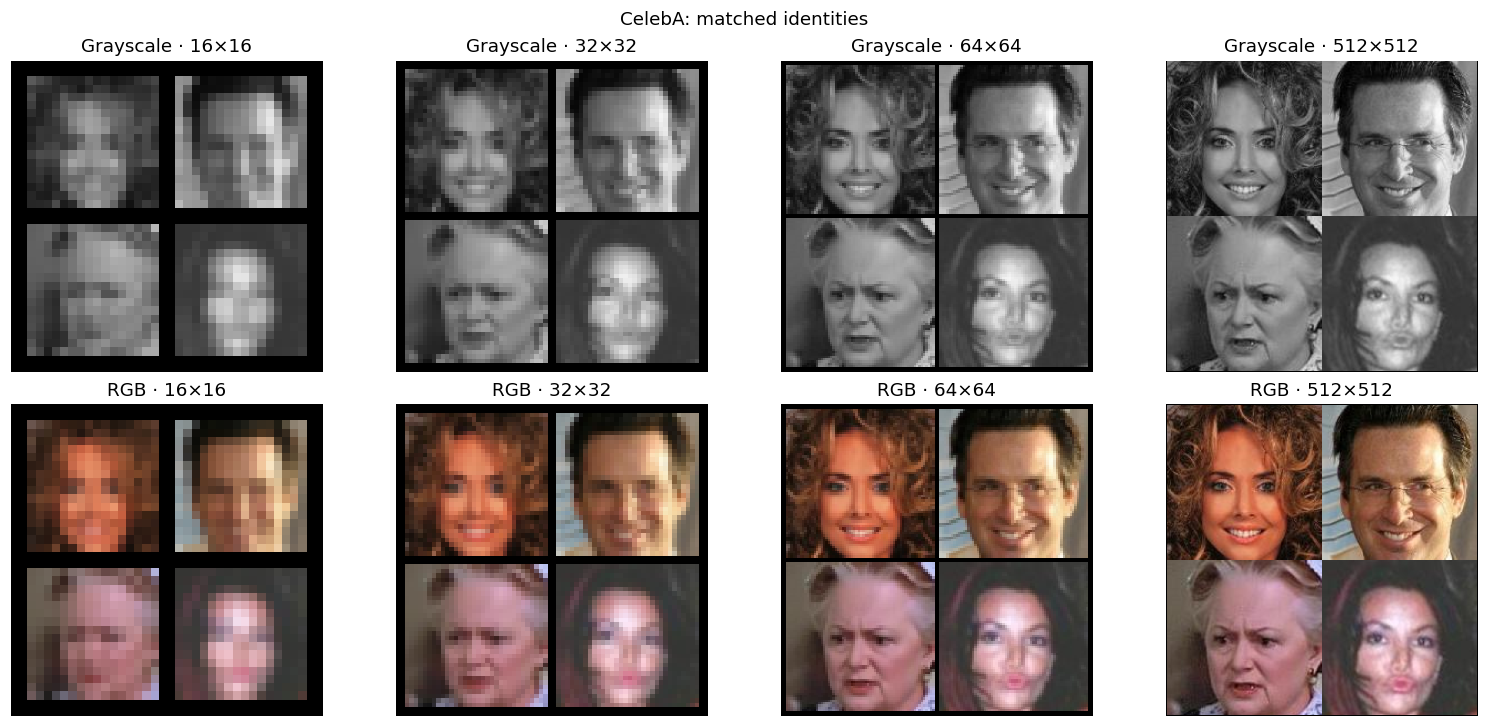

In [8]:
# Render one matched size and channel matrix for each dataset.
for dataset_key in REQUIRED_DATASETS:
    figure, axes = plt.subplots(2, 4, figsize=(14, 6.5), constrained_layout=True)
    for row, channels in enumerate(IMAGE_CHANNELS):
        for column, image_size in enumerate(IMAGE_SIZES):
            bundle = variant_bundles[(dataset_key, channels, image_size)]
            image, color_map = grid_image(bundle["train"])
            axis = axes[row, column]
            axis.imshow(image, cmap=color_map, interpolation="nearest")
            mode = "Grayscale" if channels == 1 else "RGB"
            axis.set_title(f"{mode} · {image_size}×{image_size}")
            axis.axis("off")
    figure.suptitle(f"{DISPLAY_NAMES[dataset_key]}: matched identities")
    plt.show()


## 5. Check training-set size

Request 4, 8, and 16 fixed training members from every required dataset.

A larger request must preserve the smaller seeded prefix.


In [9]:
# Load and assert each requested training-set size.
count_bundles = {}
count_rows = []
for dataset_key in REQUIRED_DATASETS:
    channels = CANONICAL_CHANNELS[dataset_key]
    previous_indices = None
    for n_train in TRAIN_COUNTS:
        bundle = load_bundle(dataset_key, 32, channels, n_train, 7)
        assert_bundle(bundle, n_train, channels, 32)
        if previous_indices is not None:
            prefix = bundle["train_indices"][: previous_indices.numel()]
            assert torch.equal(prefix, previous_indices)
        previous_indices = bundle["train_indices"].clone()
        count_bundles[(dataset_key, n_train)] = bundle
        count_rows.append(
            {
                "dataset": DISPLAY_NAMES[dataset_key],
                "n_train": n_train,
                "first_ids": bundle["train_sample_ids"][:4],
                "status": "PASS",
            }
        )

count_summary = pd.DataFrame(count_rows)
assert len(count_summary) == 12
display(count_summary)
print("PASS: all training counts are exact and prefix-stable.")


,dataset,n_train,first_ids,status
0,MNIST,4,"[21615, 50166, 37383, 3791]",PASS
1,MNIST,8,"[21615, 50166, 37383, 3791]",PASS
2,MNIST,16,"[21615, 50166, 37383, 3791]",PASS
3,CIFAR-10,4,"[41615, 33421, 9717, 7492]",PASS
4,CIFAR-10,8,"[41615, 33421, 9717, 7492]",PASS
5,CIFAR-10,16,"[41615, 33421, 9717, 7492]",PASS
6,Flowers102,4,"[315, 960, 795, 14]",PASS
7,Flowers102,8,"[315, 960, 795, 14]",PASS
8,Flowers102,16,"[315, 960, 795, 14]",PASS
9,CelebA,4,"[85605, 125431, 123051, 128217]",PASS


PASS: all training counts are exact and prefix-stable.


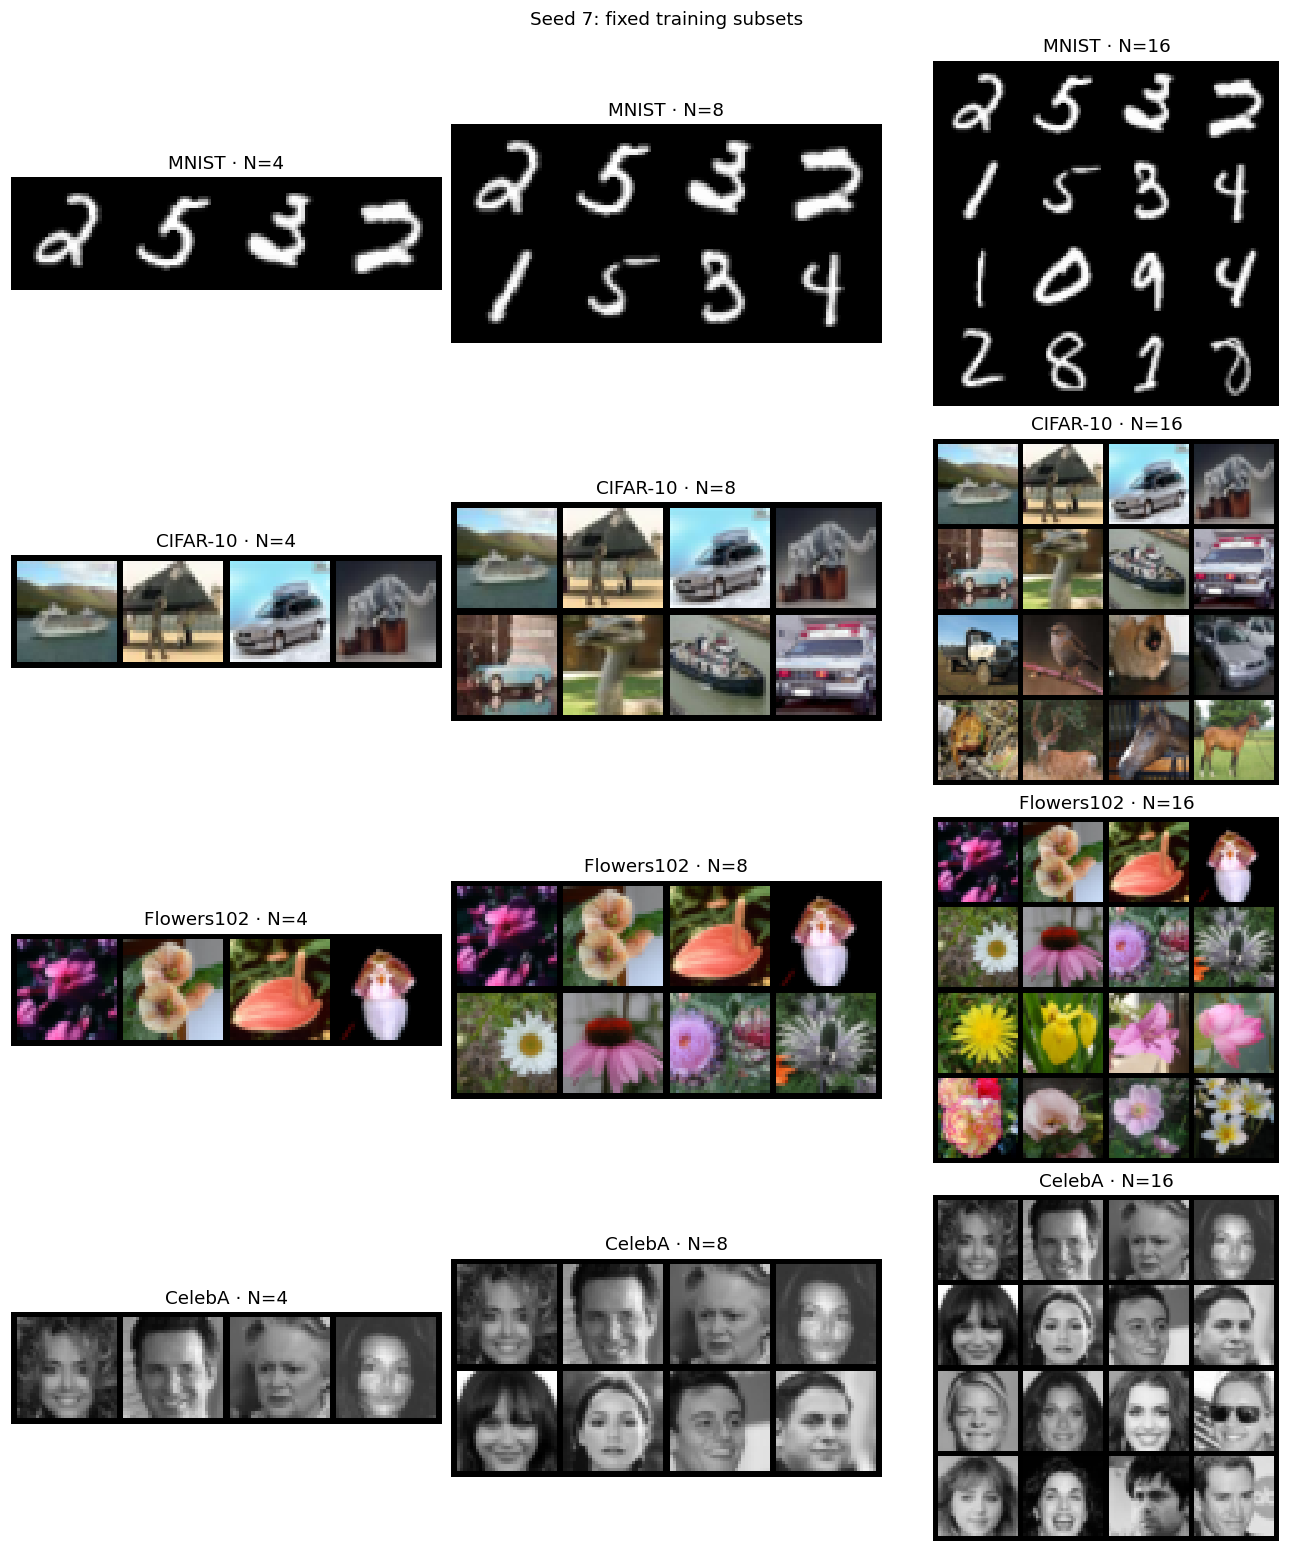

In [10]:
# Render the growing fixed subset for each dataset.
figure, axes = plt.subplots(4, 3, figsize=(12, 14), constrained_layout=True)
for row, dataset_key in enumerate(REQUIRED_DATASETS):
    for column, n_train in enumerate(TRAIN_COUNTS):
        bundle = count_bundles[(dataset_key, n_train)]
        image, color_map = grid_image(bundle["train"], nrow=4)
        axis = axes[row, column]
        axis.imshow(image, cmap=color_map, interpolation="nearest")
        axis.set_title(f"{DISPLAY_NAMES[dataset_key]} · N={n_train}")
        axis.axis("off")
figure.suptitle("Seed 7: fixed training subsets")
plt.show()


## 6. Check seed behavior

Compare two seeds with eight training members from every required dataset.

Different seeds must change membership. Identical seeds must reproduce exact tensors.


In [11]:
# Load two seeds and measure their subset overlap.
seed_bundles = {}
seed_rows = []
for dataset_key in REQUIRED_DATASETS:
    channels = CANONICAL_CHANNELS[dataset_key]
    for seed in SEEDS:
        bundle = load_bundle(dataset_key, 32, channels, 8, seed)
        assert_bundle(bundle, 8, channels, 32)
        seed_bundles[(dataset_key, seed)] = bundle

    first = seed_bundles[(dataset_key, SEEDS[0])]
    second = seed_bundles[(dataset_key, SEEDS[1])]
    assert not torch.equal(first["train_indices"], second["train_indices"])
    overlap = len(set(first["train_sample_ids"]) & set(second["train_sample_ids"]))
    seed_rows.append(
        {
            "dataset": DISPLAY_NAMES[dataset_key],
            "seed_7_ids": first["train_sample_ids"],
            "seed_19_ids": second["train_sample_ids"],
            "overlap": overlap,
            "status": "PASS",
        }
    )

seed_summary = pd.DataFrame(seed_rows)
display(seed_summary)
print("PASS: different seeds select different training subsets.")


,dataset,seed_7_ids,seed_19_ids,overlap,status
0,MNIST,"[21615, 50166, 37383, 3791, 38823, 45497, 5004...","[43645, 37773, 11635, 46051, 41216, 6464, 5042...",0,PASS
1,CIFAR-10,"[41615, 33421, 9717, 7492, 3935, 5537, 32205, ...","[3645, 33936, 23433, 23781, 25360, 37674, 4229...",0,PASS
2,Flowers102,"[315, 960, 795, 14, 487, 177, 281, 343]","[865, 872, 489, 985, 300, 1019, 992, 439]",0,PASS
3,CelebA,"[85605, 125431, 123051, 128217, 76199, 145172,...","[96435, 116657, 21831, 22016, 7252, 41049, 159...",0,PASS


PASS: different seeds select different training subsets.


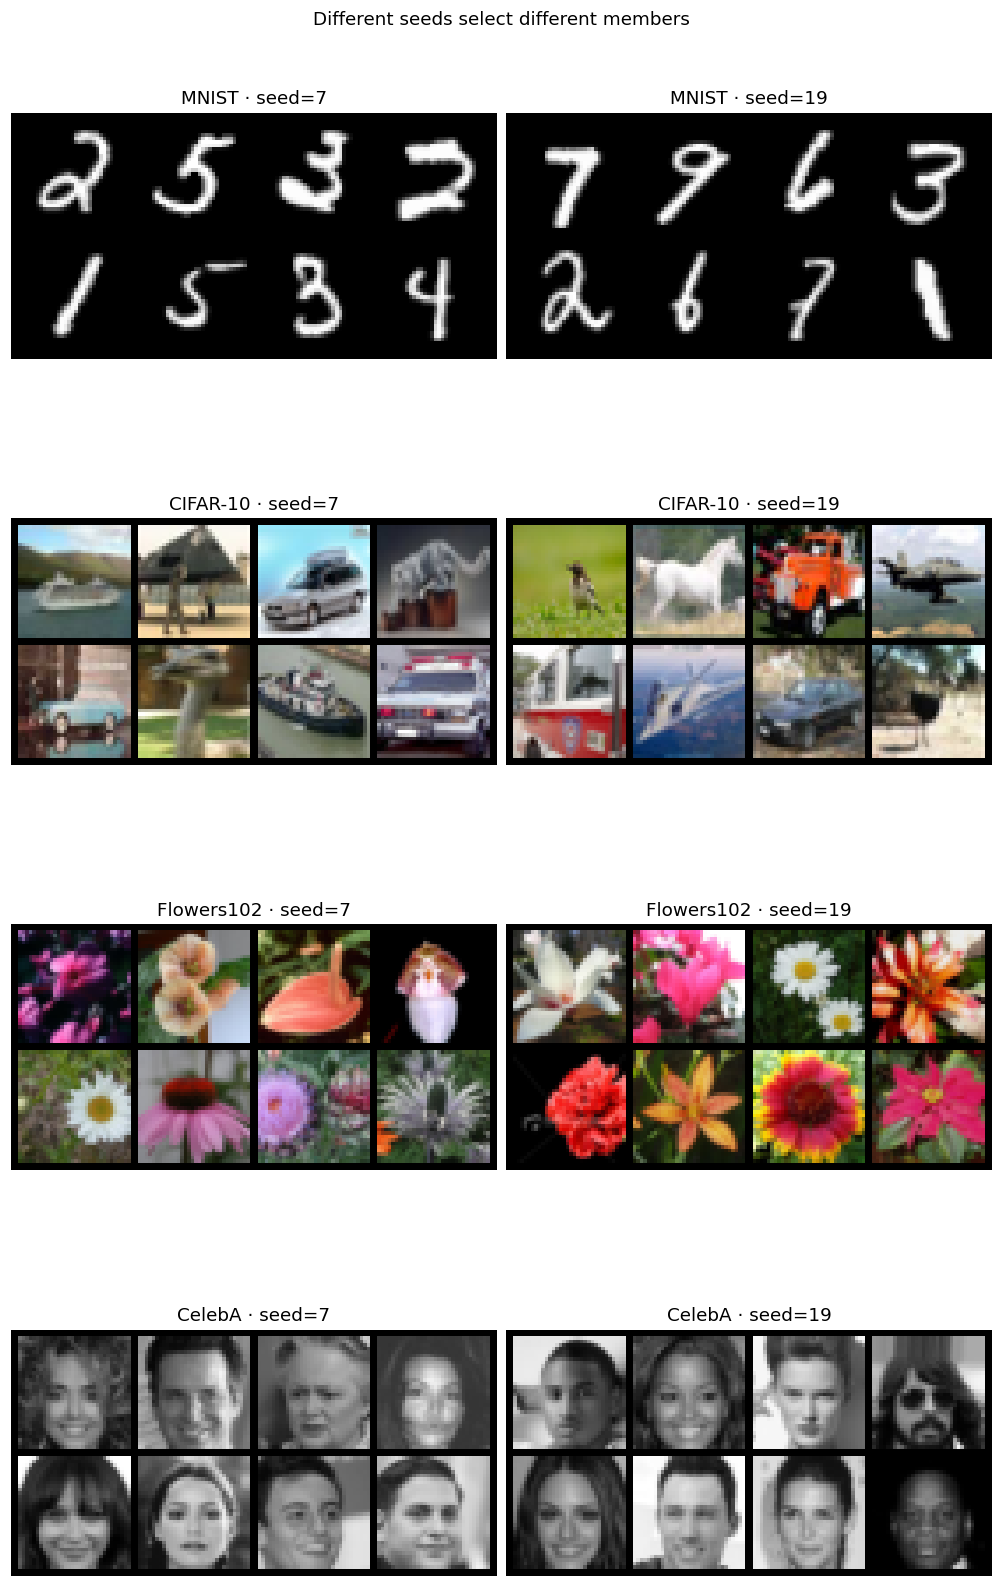

In [12]:
# Render the two seeded subsets for direct comparison.
figure, axes = plt.subplots(4, 2, figsize=(9, 15), constrained_layout=True)
for row, dataset_key in enumerate(REQUIRED_DATASETS):
    for column, seed in enumerate(SEEDS):
        bundle = seed_bundles[(dataset_key, seed)]
        image, color_map = grid_image(bundle["train"], nrow=4)
        axis = axes[row, column]
        axis.imshow(image, cmap=color_map, interpolation="nearest")
        axis.set_title(f"{DISPLAY_NAMES[dataset_key]} · seed={seed}")
        axis.axis("off")
figure.suptitle("Different seeds select different members")
plt.show()


## 7. Confirm fixed preprocessing

Reload each baseline configuration without the cache.

Zero tensor difference confirms deterministic preprocessing without random augmentation.


In [13]:
# Reload each baseline and compare exact tensors and identities.
repeat_rows = []
for dataset_key in REQUIRED_DATASETS:
    channels = CANONICAL_CHANNELS[dataset_key]
    original = load_bundle(dataset_key, 32, channels, 4, 7)
    repeated = build_data_bundle(make_config(dataset_key, 32, channels, 4, 7))
    max_difference = float((original["train"] - repeated["train"]).abs().max())
    same_indices = torch.equal(original["train_indices"], repeated["train_indices"])
    assert max_difference == 0.0
    assert same_indices
    repeat_rows.append(
        {
            "dataset": DISPLAY_NAMES[dataset_key],
            "max_tensor_difference": max_difference,
            "same_indices": same_indices,
            "status": "PASS",
        }
    )

repeat_summary = pd.DataFrame(repeat_rows)
display(repeat_summary)
print("PASS: identical configurations reproduce exact fixed tensors.")


,dataset,max_tensor_difference,same_indices,status
0,MNIST,0.0,True,PASS
1,CIFAR-10,0.0,True,PASS
2,Flowers102,0.0,True,PASS
3,CelebA,0.0,True,PASS


PASS: identical configurations reproduce exact fixed tensors.


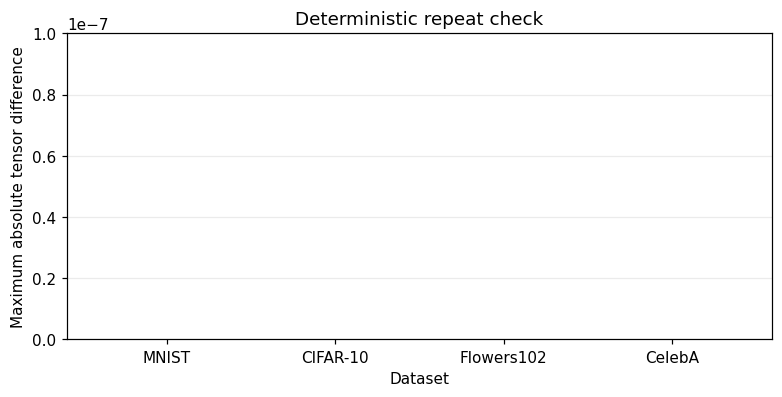

In [14]:
# Plot the exact repeat difference for each dataset.
figure, axis = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
axis.bar(repeat_summary["dataset"], repeat_summary["max_tensor_difference"])
axis.set_title("Deterministic repeat check")
axis.set_xlabel("Dataset")
axis.set_ylabel("Maximum absolute tensor difference")
axis.set_ylim(0.0, 1.0e-7)
axis.grid(axis="y", alpha=0.25)
plt.show()


## 8. Final verdict

Summarize only evidence produced during this notebook execution.


In [15]:
# Assemble one final verification table.
verdict = pd.DataFrame(
    [
        {"check": "Required local datasets", "result": "4/4 PASS"},
        {"check": "Baseline bundle contract", "result": "4/4 PASS"},
        {"check": "Size and channel variants", "result": "32/32 PASS"},
        {"check": "Training-set sizes", "result": "12/12 PASS"},
        {"check": "Different seed membership", "result": "4/4 PASS"},
        {"check": "Deterministic repeats", "result": "4/4 PASS"},
        {"check": "AFHQ-v2", "result": "NOT TESTED: data unavailable"},
        {"check": "FFHQ128", "result": "NOT TESTED: data unavailable"},
    ]
)
display(verdict)

assert variant_summary["status"].eq("PASS").all()
assert count_summary["status"].eq("PASS").all()
assert seed_summary["status"].eq("PASS").all()
assert repeat_summary["status"].eq("PASS").all()
print("VERIFIED: every available first-party image loader passed all checks.")


,check,result
0,Required local datasets,4/4 PASS
1,Baseline bundle contract,4/4 PASS
2,Size and channel variants,32/32 PASS
3,Training-set sizes,12/12 PASS
4,Different seed membership,4/4 PASS
5,Deterministic repeats,4/4 PASS
6,AFHQ-v2,NOT TESTED: data unavailable
7,FFHQ128,NOT TESTED: data unavailable


VERIFIED: every available first-party image loader passed all checks.


## Interpretation

The available loaders produce fixed, finite, normalized tensors with stable source identities.

Image size and channel changes preserve membership because they only change preprocessing.

Training-set size changes preserve one seeded ordering. Seed changes select different members.

AFHQ-v2 and FFHQ128 require local data before equivalent claims are valid.
